# Stage 4: gradient-boosting models (LightGBM and XGBoost)

This notebook only **shows** results. The work is done by two scripts:

- `python -m src.tune_gbm --horizon <h> --trials 20` : random search, validation only;
- `python -m src.train_gbm` : final refit on train + validation, one test run, saved models.

**Why tree ensembles?** The features are a table (lags, weather, sun position, calendar). Trees handle
missing values, need no scaling, and learn interactions (for example: irradiance matters differently
at noon and at sunset) without us writing them by hand.

**How was the test set kept clean?** Every setting is fitted on *train* and scored on *validation*
(early stopping also on validation). The best setting and its number of trees are fixed. Only then is
the model refit on train + validation and the 2023 test year scored **once**.

In [1]:
import pandas as pd
from IPython.display import Image

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
TABLES = "../results/tables/"
FIGURES = "../results/figures/"

## 1. Tuning log
Every setting that was tried. The lowest validation RMSE per model and horizon wins.

In [2]:
log = pd.read_csv(TABLES + "04_tuning_log.csv")
log.groupby(["horizon", "model"])["val_rmse"].agg(["count", "min", "median", "max"]).round(5)

count      min   median      max
horizon  model                                  
15min    lgbm      20  0.05642  0.05687  0.05823
         xgb       20  0.05628  0.05687  0.05804
1h       lgbm      20  0.06114  0.06257  0.06452
         xgb       20  0.06058  0.06188  0.06496
dayahead lgbm      20  0.11707  0.12159  0.12727
         xgb       20  0.11697  0.12300  0.12875

In [3]:
best = log.loc[log.groupby(["horizon", "model"])["val_rmse"].idxmin()]
best[["horizon", "model", "trial", "val_rmse", "n_trees", "params"]]

,horizon,model,trial,val_rmse,n_trees,params
95,15min,lgbm,16,0.056419,170,"{""learning_rate"": 0.05, ""num_leaves"": 127, ""mi..."
101,15min,xgb,2,0.056277,371,"{""learning_rate"": 0.02, ""max_depth"": 8, ""min_c..."
0,1h,lgbm,1,0.061141,324,"{""learning_rate"": 0.02, ""num_leaves"": 127, ""mi..."
36,1h,xgb,17,0.060581,215,"{""learning_rate"": 0.03, ""max_depth"": 8, ""min_c..."
57,dayahead,lgbm,18,0.117073,32,"{""learning_rate"": 0.12, ""num_leaves"": 15, ""min..."
72,dayahead,xgb,13,0.116968,65,"{""learning_rate"": 0.05, ""max_depth"": 4, ""min_c..."


## 2. Test results next to the baselines
Daytime, seen stations, 2023. `skill` = 1 - RMSE / RMSE of the benchmark persistence.

In [4]:
baselines = pd.read_csv(TABLES + "03_baselines.csv")
gbm = pd.read_csv(TABLES + "04_gbm_results.csv")
both = pd.concat([baselines, gbm])

In [5]:
test = both[(both["split"] == "test") & (both["hours"] == "daytime")]
columns = ["horizon", "model", "nmae_pct", "nmae_pct_low", "nmae_pct_high", "skill", "skill_low", "skill_high", "mean_station_skill"]
test[columns].sort_values(["horizon", "nmae_pct"]).round(3)

,horizon,model,nmae_pct,nmae_pct_low,nmae_pct_high,skill,skill_low,skill_high,mean_station_skill
7,15min,xgb,4.609,4.338,4.881,0.112,0.099,0.124,0.110
3,15min,lgbm,4.646,4.375,4.922,0.109,0.097,0.120,0.106
10,15min,smart_persistence,4.692,4.386,5.002,0.031,0.027,0.035,0.031
11,15min,ridge,4.975,4.726,5.229,0.090,0.082,0.097,0.087
9,15min,last_value,5.323,5.005,5.623,0.000,0.000,0.000,0.000
15,1h,xgb,4.949,4.718,5.203,0.346,0.321,0.369,0.340
11,1h,lgbm,4.953,4.717,5.199,0.348,0.324,0.370,0.342
22,1h,smart_persistence,5.672,5.417,5.937,0.277,0.257,0.297,0.278
23,1h,ridge,5.707,5.491,5.940,0.306,0.283,0.328,0.295
21,1h,last_value,9.005,8.629,9.331,0.000,0.000,0.000,0.000


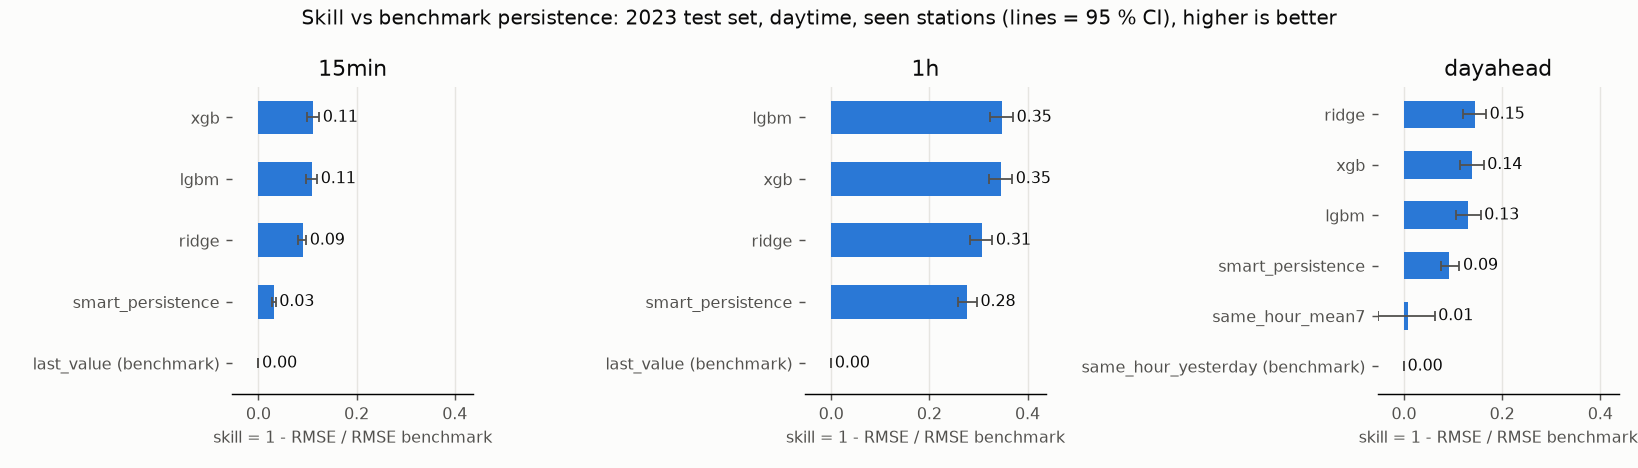

In [6]:
Image(FIGURES + "04_gbm_skill.png")

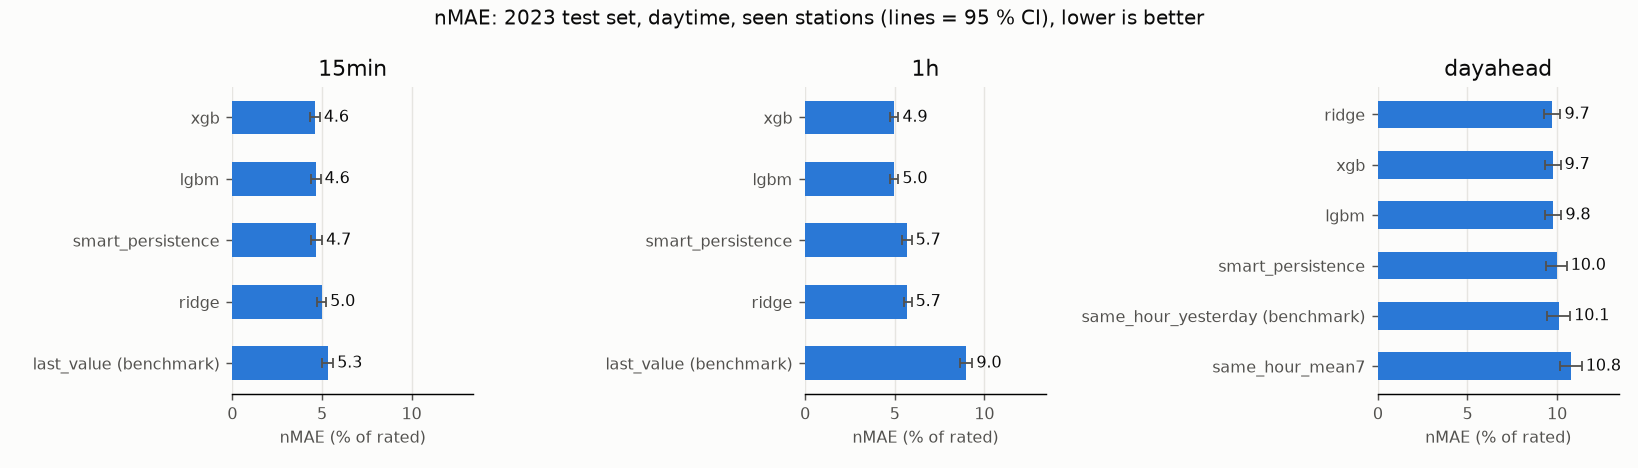

In [7]:
Image(FIGURES + "04_gbm_nmae.png")

## 3. All hours
Night targets are 0 and night forecasts are 0 by rule, so all-hours errors are smaller. Skill is almost the same.

In [8]:
all_hours = both[(both["split"] == "test") & (both["hours"] == "all")]
all_hours[["horizon", "model", "nmae_pct", "skill"]].sort_values(["horizon", "nmae_pct"]).round(3)

,horizon,model,nmae_pct,skill
6,15min,xgb,2.156,0.112
2,15min,lgbm,2.173,0.109
7,15min,smart_persistence,2.195,0.031
8,15min,ridge,2.327,0.090
6,15min,last_value,2.490,0.000
14,1h,xgb,2.277,0.345
10,1h,lgbm,2.279,0.347
19,1h,smart_persistence,2.608,0.277
20,1h,ridge,2.624,0.306
18,1h,last_value,4.134,0.000


## 4. Validation vs test
Validation is one dry season (Oct-Dec 2022); the test year has all seasons, so the errors differ.

In [9]:
day = gbm[gbm["hours"] == "daytime"]
day.pivot(index=["horizon", "model"], columns="split", values=["nmae_pct", "skill"]).round(3)

nmae_pct         skill       
split              test    val   test    val
horizon  model                              
15min    lgbm     4.646  3.232  0.109  0.150
         xgb      4.609  3.225  0.112  0.152
1h       lgbm     4.953  3.965  0.348  0.475
         xgb      4.949  3.907  0.346  0.480
dayahead lgbm     9.779  8.477  0.131  0.106
         xgb      9.750  8.552  0.140  0.106

## 5. Per season (test, daytime)

In [10]:
season = pd.read_csv(TABLES + "04_gbm_per_season.csv")
season.pivot(index=["horizon", "model"], columns="season", values="nmae_pct").round(2)

season          autumn  spring  summer  winter
horizon  model                                
15min    lgbm     3.90    3.91    7.21    3.11
         xgb      3.87    3.86    7.14    3.12
1h       lgbm     4.47    4.58    6.59    3.78
         xgb      4.47    4.53    6.61    3.79
dayahead lgbm     9.60   10.28   10.18    8.83
         xgb      9.68   10.30   10.06    8.74

In [11]:
season.pivot(index=["horizon", "model"], columns="season", values="skill").round(3)

season          autumn  spring  summer  winter
horizon  model                                
15min    lgbm    0.123   0.075   0.117   0.099
         xgb     0.128   0.080   0.123   0.083
1h       lgbm    0.423   0.325   0.277   0.458
         xgb     0.426   0.325   0.272   0.456
dayahead lgbm    0.127   0.142   0.153   0.074
         xgb     0.128   0.143   0.165   0.097

## 6. Per station (test, daytime)
Spread of the skill over the stations: is the model better than persistence everywhere?

In [12]:
station = pd.read_csv(TABLES + "04_gbm_per_station.csv")
station.groupby(["horizon", "model"])["skill"].describe().round(3)

count   mean    std    min    25%    50%    75%    max
horizon  model                                                        
15min    lgbm    24.0  0.106  0.014  0.062  0.102  0.109  0.115  0.121
         xgb     24.0  0.110  0.012  0.075  0.108  0.113  0.118  0.124
1h       lgbm    43.0  0.342  0.040  0.219  0.335  0.351  0.365  0.417
         xgb     43.0  0.340  0.038  0.208  0.336  0.350  0.361  0.418
dayahead lgbm    43.0  0.114  0.108 -0.481  0.128  0.137  0.151  0.166
         xgb     43.0  0.120  0.121 -0.529  0.134  0.150  0.162  0.172

In [13]:
worst = station.sort_values("skill").groupby(["horizon", "model"]).head(3)
worst[["horizon", "model", "station", "nmae_pct", "skill"]].round(3)

,horizon,model,station,nmae_pct,skill
202,dayahead,xgb,SQ567 Flexible PV,7.866,-0.529
159,dayahead,lgbm,SQ567 Flexible PV,7.416,-0.481
210,dayahead,xgb,UG Hall7 Flexible PV,6.369,-0.246
167,dayahead,lgbm,UG Hall7 Flexible PV,5.857,-0.181
206,dayahead,xgb,UG Hall2 2F,7.475,0.001
163,dayahead,lgbm,UG Hall2 2F,7.258,0.004
13,15min,lgbm,UG Hall2 2F,3.054,0.062
37,15min,xgb,UG Hall2 2F,2.992,0.075
23,15min,lgbm,Zone J2,3.538,0.079
47,15min,xgb,Zone J2,3.512,0.083
